<a href="https://colab.research.google.com/github/pajola/secai-course/blob/main/module-01-adversarial-ml/01_adversarial_examples_images.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" height="32"></a>

# 1 · Adversarial Examples on Images — attacks, transferability, defenses

**SecAI course · Adversarial Machine Learning, part 1**

In this notebook we will:

1. train a small CNN on MNIST (≈98% accuracy);
2. break it with **FGSM** and **PGD** — the two "reference" white-box evasion attacks;
3. craft a **targeted** adversarial example ("make this 3 look like a 7 to the model");
4. show **transferability**: adversarial examples crafted against one model fool *other* models — the key enabler of black-box attacks;
5. look at two defenses: **adversarial training** (works, at a cost) and **input preprocessing** (looks like it works … until you attack it properly).

### Threat model (always state it!)

| | Evasion attack (this notebook) |
|---|---|
| **Goal** | make a *correctly classified* test input be misclassified (integrity violation at inference time) |
| **Knowledge** | white-box: full access to model weights & gradients. Later: black-box via transfer |
| **Capability** | modify the input $x$ within a budget: $\|x_{adv} - x\|_\infty \le \varepsilon$ (every pixel moves by at most $\varepsilon$) |

Pixels are in $[0,1]$, so $\varepsilon = 0.1$ means "each pixel may change by at most 10% of its range".

In [1]:
# Setup — on Google Colab, fetch the course helper module (all other packages are preinstalled).
import os, sys, urllib.request
if "google.colab" in sys.modules and not os.path.exists("secai_utils.py"):
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/pajola/secai-course/main/module-01-adversarial-ml/secai_utils.py", "secai_utils.py")

device: cpu


torch.Size([20000, 1, 28, 28]) torch.Size([2000, 1, 28, 28])


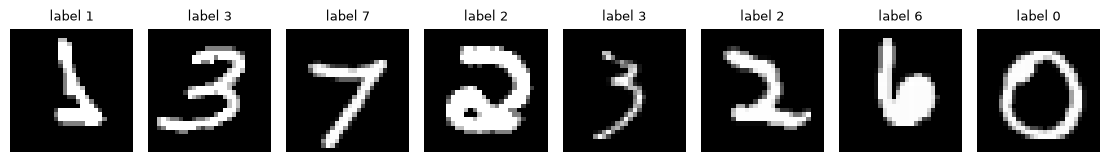

In [2]:
import numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from secai_utils import *   # load_mnist, SmallCNN, MLP, train, predict, accuracy, show_images, DEVICE

seed_everything(0)
print("device:", DEVICE)

# A 20k/2k subset keeps every cell under ~1 minute on a laptop CPU. Use None for the full dataset.
x_train, y_train, x_test, y_test = load_mnist(n_train=20_000, n_test=2_000)
print(x_train.shape, x_test.shape)
show_images(x_test[:8], titles=[f"label {int(t)}" for t in y_test[:8]])

## 1.1 The victim model

In [3]:
model = train(SmallCNN(), x_train, y_train, epochs=3)
print(f"clean test accuracy: {accuracy(model, x_test, y_test):.3f}")

epoch 1/3  loss=0.4734  train_acc=0.8558  (6s)


epoch 2/3  loss=0.1132  train_acc=0.9670  (12s)


epoch 3/3  loss=0.0745  train_acc=0.9783  (19s)


clean test accuracy: 0.978


## 1.2 FGSM — Fast Gradient Sign Method (Goodfellow et al., 2015)

Training moves the *weights* down the loss gradient. An evasion attack moves the *input* **up** the loss gradient instead:

$$x_{adv} = \text{clip}_{[0,1]}\big(x + \varepsilon \cdot \text{sign}(\nabla_x \mathcal{L}(f_\theta(x), y))\big)$$

One gradient computation, one step. Taking the `sign` spends the whole $L_\infty$ budget on every pixel at once.

This is an **untargeted** attack: we pass the *true* label $y$ and push the loss on it **up** — any wrong prediction counts as success. (Targeted attacks, where the attacker picks the output, are in §1.4.)

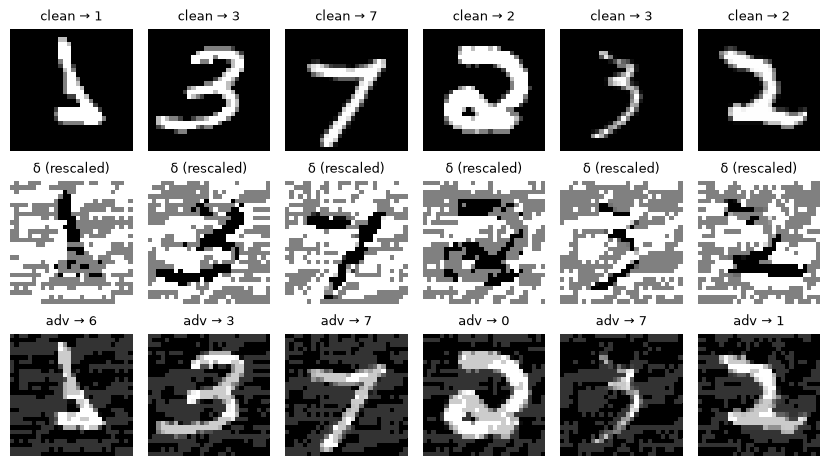

In [4]:
def fgsm(model, x, y, eps):
    dev = x.device                                   # return on the caller's device (CPU tensors stay on CPU when a GPU is used)
    x = x.clone().detach().to(DEVICE).requires_grad_(True)
    loss = F.cross_entropy(model(x), y.to(DEVICE))
    grad, = torch.autograd.grad(loss, x)
    return (x + eps * grad.sign()).clamp(0, 1).detach().to(dev)

def show_attack(model, x, y, x_adv, n=6):
    pred_clean = predict(model, x[:n]).argmax(1)
    pred_adv   = predict(model, x_adv[:n]).argmax(1)
    delta = (x_adv[:n] - x[:n])
    delta_vis = (delta - delta.min()) / (delta.max() - delta.min() + 1e-8)   # rescale for display only
    imgs   = torch.cat([x[:n], delta_vis, x_adv[:n]])
    titles = [f"clean → {int(p)}" for p in pred_clean] + ["δ (rescaled)"] * n + [f"adv → {int(p)}" for p in pred_adv]
    show_images(imgs, titles=titles, n_cols=n)

x_adv = fgsm(model, x_test[:6], y_test[:6], eps=0.2)
show_attack(model, x_test, y_test, x_adv)

The perturbation looks like structured noise to us, yet the predictions flip. The images are still obviously the same digits — **the model is wrong, not the human**.

## 1.3 PGD — Projected Gradient Descent (Madry et al., 2018)

FGSM is a single, coarse step. PGD takes many small steps and, after each one, **projects** back into the $\varepsilon$-ball around the original image:

$$x^{t+1} = \Pi_{B_\varepsilon(x)}\Big(x^t + \alpha \cdot \text{sign}(\nabla_x \mathcal{L}(f_\theta(x^t), y))\Big)$$

It is the strongest "first-order" attack and the standard yardstick for evaluating robustness. Like FGSM above, this is the **untargeted** version (the `targeted=True` flag is used in §1.4).

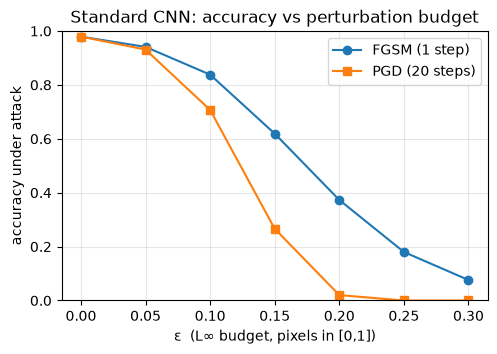

eps=0.00   FGSM acc=0.979   PGD acc=0.979
eps=0.05   FGSM acc=0.941   PGD acc=0.931
eps=0.10   FGSM acc=0.838   PGD acc=0.707
eps=0.15   FGSM acc=0.619   PGD acc=0.266
eps=0.20   FGSM acc=0.373   PGD acc=0.020
eps=0.25   FGSM acc=0.180   PGD acc=0.000
eps=0.30   FGSM acc=0.076   PGD acc=0.000


In [5]:
def pgd(model, x, y, eps, alpha=None, steps=20, random_start=True, targeted=False):
    alpha = alpha or 2.5 * eps / steps          # rule of thumb: can traverse the ball ~2.5 times
    dev = x.device
    x, y = x.to(DEVICE), y.to(DEVICE)
    x_adv = x.clone().detach()
    if random_start:
        x_adv = (x_adv + torch.empty_like(x_adv).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv, allow_unused=True)
        grad = torch.zeros_like(x_adv) if grad is None else grad          # (a defense may cut the gradient entirely)
        step = -alpha * grad.sign() if targeted else alpha * grad.sign()   # targeted: *minimise* loss w.r.t. target
        x_adv = x_adv.detach() + step
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)  # projection onto the eps-ball ∩ [0,1]
    return x_adv.detach().to(dev)

def robust_accuracy(model, attack, x, y, batch_size=500, **kw):
    correct = 0
    for i in range(0, len(x), batch_size):
        xa = attack(model, x[i:i+batch_size], y[i:i+batch_size], **kw)
        correct += (predict(model, xa).argmax(1) == y[i:i+batch_size]).sum().item()
    return correct / len(x)

eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]
acc_fgsm = [robust_accuracy(model, fgsm, x_test[:1000], y_test[:1000], eps=e) for e in eps_grid]
acc_pgd  = [robust_accuracy(model, pgd,  x_test[:1000], y_test[:1000], eps=e) for e in eps_grid]

plt.figure(figsize=(5.5, 3.5))
plt.plot(eps_grid, acc_fgsm, "o-", label="FGSM (1 step)")
plt.plot(eps_grid, acc_pgd,  "s-", label="PGD (20 steps)")
plt.xlabel("ε  (L∞ budget, pixels in [0,1])"); plt.ylabel("accuracy under attack"); plt.ylim(0, 1)
plt.title("Standard CNN: accuracy vs perturbation budget"); plt.legend(); plt.grid(alpha=.3); plt.show()
for e, a, b in zip(eps_grid, acc_fgsm, acc_pgd):
    print(f"eps={e:.2f}   FGSM acc={a:.3f}   PGD acc={b:.3f}")

With a budget of $\varepsilon = 0.2$ (humans barely notice on MNIST), PGD drives a 99%-accurate model to ~0%.
MNIST is actually one of the *easiest* datasets to defend; on natural images (CIFAR-10, ImageNet) models break at $\varepsilon \approx 8/255 \approx 0.03$.

## 1.4 Untargeted vs targeted attacks

Everything so far was **untargeted**: the attacker only wants the model to be *wrong*, and does not care which wrong label comes out.
A **targeted** attack chooses the output: *"make this 3 be read as a 7"*. The algorithm is the same PGD; only two things change — which label goes into the loss, and the sign of the step.

| | Untargeted (§1.2–1.3) | Targeted (this section) |
|---|---|---|
| **Attacker's goal** | any wrong label: $f(x_{adv}) \neq y$ | one chosen label $t$: $f(x_{adv}) = t$ |
| **Label fed to the loss** | the **true** label $y$ | the **target** label $t$ |
| **Step** | gradient **ascent**: $x + \alpha\,\text{sign}(\nabla_x \mathcal{L}(f(x), y))$ — move *away* from $y$ | gradient **descent**: $x - \alpha\,\text{sign}(\nabla_x \mathcal{L}(f(x), t))$ — move *towards* $t$ |
| **Call in this notebook** | `pgd(model, x, y, eps)` | `pgd(model, x, t, eps, targeted=True)` |
| **Success means** | prediction $\neq y$ | prediction $= t$ |
| **Difficulty** | easier: the nearest wrong class is enough | harder: must reach one specific class — usually needs more ε or more steps |
| **Real-world example** | evade a malware / spam detector (any "benign" label will do) | stop sign → "speed limit 45"; impersonate a *specific* person in face recognition |

Below we attack the **same 8 digits** both ways, with the same budget (ε = 0.25, 40 steps), so the only difference is the goal.


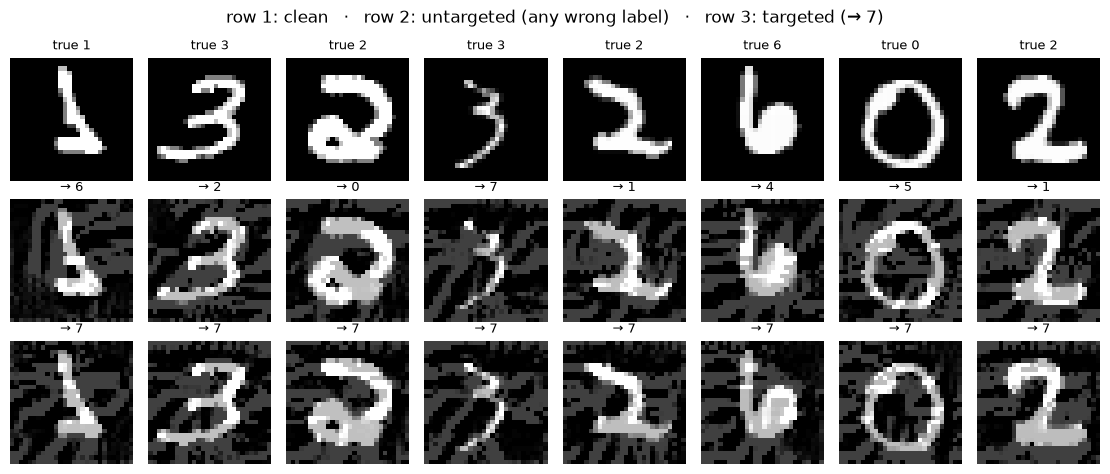

untargeted success (prediction ≠ true label): 1.00   labels reached: [6, 2, 0, 7, 1, 4, 5, 1]
targeted success   (prediction = 7):           1.00   labels reached: [7, 7, 7, 7, 7, 7, 7, 7]


In [6]:
TARGET = 7
mask = y_test[:200] != TARGET
x_src, y_src = x_test[:200][mask][:8], y_test[:200][mask][:8]
y_target = torch.full_like(y_src, TARGET)

x_u = pgd(model, x_src, y_src,    eps=0.25, steps=40)                  # untargeted: true labels, loss goes UP
x_t = pgd(model, x_src, y_target, eps=0.25, steps=40, targeted=True)   # targeted: target labels, loss goes DOWN
pred_u = predict(model, x_u).argmax(1)
pred_t = predict(model, x_t).argmax(1)
show_images(torch.cat([x_src, x_u, x_t]), n_cols=8,
            titles=[f"true {int(t)}" for t in y_src] + [f"→ {int(p)}" for p in pred_u] + [f"→ {int(p)}" for p in pred_t],
            suptitle=f"row 1: clean   ·   row 2: untargeted (any wrong label)   ·   row 3: targeted (→ {TARGET})")
print(f"untargeted success (prediction ≠ true label): {(pred_u != y_src).float().mean().item():.2f}   labels reached: {pred_u.tolist()}")
print(f"targeted success   (prediction = {TARGET}):           {(pred_t == TARGET).float().mean().item():.2f}   labels reached: {pred_t.tolist()}")

**Reading the two rows.** The untargeted attack lands on whatever wrong class is *easiest to reach* from each digit, so the labels it reaches are scattered (here 8 digits end up in 6 different classes), and you cannot predict them in advance.
The targeted attack sends every digit to the same class, 7, which is a stronger and more dangerous capability: the attacker controls *what* the system does, not just *that* it fails.
Untargeted success is the standard metric for robustness (it is the defender's worst case); targeted success is what most concrete attacks in the real world need.

## 1.5 Transferability — why black-box attacks work

So far we used the victim's gradients (white-box). In practice the attacker often has **no access** to the deployed model.
Key empirical fact (Szegedy et al. 2014, Papernot et al. 2016): adversarial examples crafted on a *surrogate* model
frequently fool *other* models trained on similar data — even with a **different architecture**.

Let's train two more, independent models and build the transfer matrix *source model → target model*.

CNN (victim)                   clean acc = 0.978
MLP                            clean acc = 0.944
CNN-2 (narrower, other seed)   clean acc = 0.969


FGSM, ε=0.2: rows = crafted on, cols = evaluated on
 [[0.373 0.404 0.728]
 [0.799 0.    0.621]
 [0.682 0.23  0.293]]


PGD, ε=0.2: rows = crafted on, cols = evaluated on
 [[0.018 0.349 0.572]
 [0.826 0.    0.695]
 [0.483 0.176 0.036]]


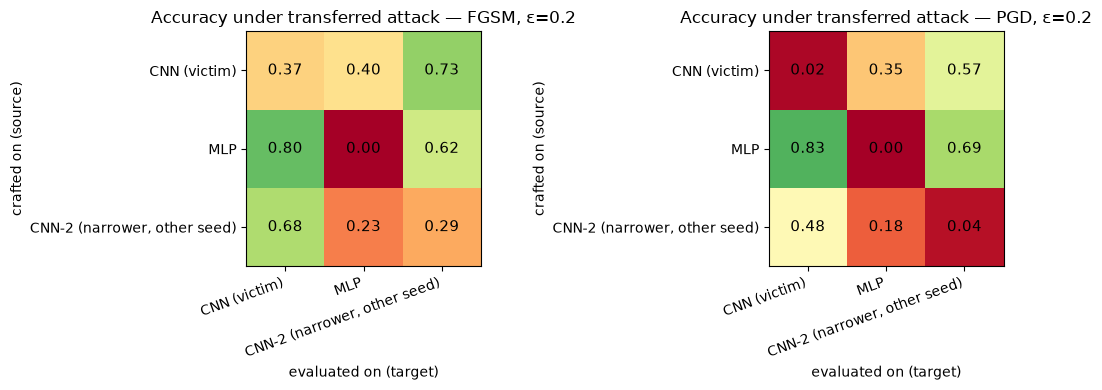

In [7]:
seed_everything(1); model_mlp  = train(MLP(),            x_train, y_train, epochs=3, verbose=False)
seed_everything(2); model_cnn2 = train(SmallCNN(width=16), x_train, y_train, epochs=2, verbose=False)

models = {"CNN (victim)": model, "MLP": model_mlp, "CNN-2 (narrower, other seed)": model_cnn2}
for name, m in models.items():
    print(f"{name:30s} clean acc = {accuracy(m, x_test, y_test):.3f}")

def transfer_matrix(attack, eps, n=1000):
    names = list(models)
    M = np.zeros((len(names), len(names)))
    for i, src in enumerate(names):
        x_adv = torch.cat([attack(models[src], x_test[j:j+500], y_test[j:j+500], eps=eps) for j in range(0, n, 500)])
        for j, tgt in enumerate(names):
            M[i, j] = (predict(models[tgt], x_adv).argmax(1) == y_test[:n]).float().mean().item()
    return names, M

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (attack, title) in zip(axes, [(fgsm, "FGSM, ε=0.2"), (pgd, "PGD, ε=0.2")]):
    names, M = transfer_matrix(attack, eps=0.2)
    im = ax.imshow(M, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(3)); ax.set_xticklabels(names, rotation=20, ha="right"); ax.set_yticks(range(3)); ax.set_yticklabels(names)
    ax.set_xlabel("evaluated on (target)"); ax.set_ylabel("crafted on (source)"); ax.set_title(f"Accuracy under transferred attack — {title}")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{M[i,j]:.2f}", ha="center", va="center", fontsize=11)
    print(f"{title}: rows = crafted on, cols = evaluated on\n", np.round(M, 3))
plt.tight_layout(); plt.show()

**Reading the matrix.** The diagonal is the white-box case (near 0 accuracy). Off-diagonal cells are *black-box* attacks: the attacker never touched the target model, yet accuracy drops from 0.98 to well below.

Points worth making to the class (exact numbers vary with seeds, the patterns are stable):

* Transfer is **asymmetric** and depends on the *source*: examples crafted on a CNN transfer well to everything, while the MLP's examples barely hurt the CNNs. A higher-capacity surrogate that learns "more general" features is the better attacker's tool.
* Architecture matters less than you might hope: here the CNN's examples hurt the MLP *more* than the sibling CNN.
* Stronger white-box attack ≠ stronger transfer in general: multi-step PGD can "overfit" the exact decision boundary of the source. At this ε PGD still transfers a bit better than FGSM; the literature's standard tricks to boost transfer are ensembles of surrogates, momentum and input diversity (Dong et al. 2018, Xie et al. 2019).

Implication for defenders: *"the attacker doesn't have my weights"* is **not** a security argument.

## 1.6 Defense 1 — Adversarial training (Madry et al., 2018)

The only defense that has reliably survived scrutiny: train on adversarial examples generated **on the fly** at every step,

$$\min_\theta \; \mathbb{E}_{(x,y)} \Big[ \max_{\|\delta\|_\infty \le \varepsilon} \mathcal{L}(f_\theta(x+\delta), y) \Big]$$

The inner `max` is approximated with PGD. Cost: ~(steps + 1)× training time, and a drop in *clean* accuracy.

epoch 1/5  loss=1.8656  train_acc=0.3688  (24s)


epoch 2/5  loss=1.0652  train_acc=0.6255  (48s)


epoch 3/5  loss=0.8111  train_acc=0.7192  (70s)


epoch 4/5  loss=0.6915  train_acc=0.7636  (93s)


epoch 5/5  loss=0.6275  train_acc=0.7860  (115s)


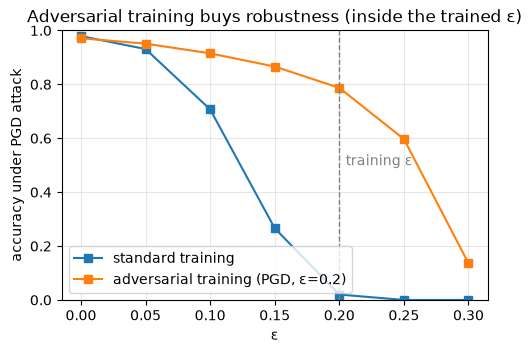

eps=0.00   standard=0.979   adv-trained=0.971
eps=0.05   standard=0.931   adv-trained=0.951
eps=0.10   standard=0.707   adv-trained=0.915
eps=0.15   standard=0.266   adv-trained=0.866
eps=0.20   standard=0.020   adv-trained=0.787
eps=0.25   standard=0.000   adv-trained=0.597
eps=0.30   standard=0.000   adv-trained=0.136


In [8]:
seed_everything(0)
at_attack = lambda m, xb, yb: pgd(m, xb, yb, eps=0.2, steps=7)      # 7-step PGD keeps this cell to a couple of minutes on CPU
model_robust = train(SmallCNN(), x_train[:10_000], y_train[:10_000], epochs=5, attack=at_attack)

acc_pgd_rob = [robust_accuracy(model_robust, pgd, x_test[:1000], y_test[:1000], eps=e) for e in eps_grid]

plt.figure(figsize=(5.5, 3.5))
plt.plot(eps_grid, acc_pgd,     "s-", label="standard training")
plt.plot(eps_grid, acc_pgd_rob, "s-", label="adversarial training (PGD, ε=0.2)")
plt.axvline(0.2, ls="--", c="gray", lw=1); plt.text(0.205, 0.5, "training ε", color="gray")
plt.xlabel("ε"); plt.ylabel("accuracy under PGD attack"); plt.ylim(0, 1); plt.legend(); plt.grid(alpha=.3)
plt.title("Adversarial training buys robustness (inside the trained ε)"); plt.show()
for e, a, b in zip(eps_grid, acc_pgd, acc_pgd_rob):
    print(f"eps={e:.2f}   standard={a:.3f}   adv-trained={b:.3f}")

Observations: a small clean-accuracy tax; strong robustness **inside** the trained budget; robustness degrades quickly **beyond** it (ε = 0.3). Robustness is always *relative to a threat model*.

## 1.7 Defense 2 — Input preprocessing (binarization)

MNIST digits are nearly black-and-white, so a cheap defense is to **binarize** the input (threshold at 0.5) before the classifier: small perturbations get rounded away.
We evaluate it three ways: (a) transfer from the undefended model, (b) naive gradient attack *through* the threshold, (c) an **adaptive** attacker who replaces the non-differentiable step by the identity in the backward pass (BPDA, Athalye et al. 2018).

In [9]:
class Binarize(torch.nn.Module):
    # Thresholding defense. `ste=True` uses a straight-through estimator so gradients flow (needed to attack it).
    def __init__(self, model, ste=False):
        super().__init__(); self.model, self.ste = model, ste
    def forward(self, x):
        xb = (x > 0.5).float()
        if self.ste:                       # forward: binarized value; backward: gradient of identity  (BPDA)
            xb = x + (xb - x).detach()
        return self.model(xb)

defended      = Binarize(model).to(DEVICE).eval()             # what the defender deploys
defended_bpda = Binarize(model, ste=True).to(DEVICE).eval()   # the attacker's differentiable approximation

xs, ys = x_test[:1000], y_test[:1000]
def acc_on(m, xa): return (predict(m, xa).argmax(1) == ys).float().mean().item()
print(f"clean accuracy, binarized model:                        {acc_on(defended, xs):.3f}")
print(f"(a) PGD crafted on the undefended model (transfer):    {acc_on(defended, pgd(model, xs, ys, eps=0.2)):.3f}")
print(f"(b) PGD through the threshold (gradient is ~0):        {acc_on(defended, pgd(defended, xs, ys, eps=0.2)):.3f}   <- meaningless number")
print(f"(c) PGD with BPDA / straight-through estimator:        {acc_on(defended, pgd(defended_bpda, xs, ys, eps=0.2)):.3f}   <- the honest number")
print(f"    ... and with eps=0.5 (enough to flip a pixel):     {acc_on(defended, pgd(defended_bpda, xs, ys, eps=0.5)):.3f}")

clean accuracy, binarized model:                        0.976


(a) PGD crafted on the undefended model (transfer):    0.919


(b) PGD through the threshold (gradient is ~0):        0.974   <- meaningless number


(c) PGD with BPDA / straight-through estimator:        0.928   <- the honest number


    ... and with eps=0.5 (enough to flip a pixel):     0.000


Honest reading: (b) is **not** a measurement — the gradient was zero, the attacker was blind. The adaptive attack (c) is the real number, and here binarization *does* help at ε = 0.2: MNIST pixels are already ≈0 or ≈1, so a perturbation smaller than 0.5 cannot flip them. That is a property of **MNIST**, not of the defense — on natural images (CIFAR, ImageNet) feature-squeezing defenses were all broken — and it is one reason MNIST is a poor robustness benchmark.

## 1.8 Gradient masking — a defense that only *looks* robust

Now a defense that *only* hides gradients. Take the same model and multiply its logits by a large temperature before the softmax (what *defensive distillation*, Papernot et al. 2016, effectively did). Predictions are unchanged, but the softmax saturates: the cross-entropy loss is exactly 0 for confident inputs and so is its gradient.

In [10]:
class Saturate(torch.nn.Module):
    def __init__(self, model, T=100.0):
        super().__init__(); self.model, self.T = model, T
    def forward(self, x): return self.model(x) * self.T

saturated = Saturate(model).to(DEVICE).eval()
print(f"clean accuracy of the saturated model: {acc_on(saturated, xs):.3f}   (same decisions as before)")
print(f"PGD with cross-entropy loss, eps=0.2:  {acc_on(saturated, pgd(saturated, xs, ys, eps=0.2)):.3f}   <- 'robust'?!")

# Adaptive attacker: don't go through the saturated softmax — use a margin loss directly on the logits (Carlini & Wagner, 2017)
def pgd_margin(model, x, y, eps, steps=20):
    alpha = 2.5 * eps / steps
    dev = x.device
    x, y = x.to(DEVICE), y.to(DEVICE)
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        z = model(x_adv)
        z_true = z.gather(1, y[:, None])[:, 0]
        z_other = z.scatter(1, y[:, None], -1e9).max(1).values
        loss = (z_other - z_true).sum()                 # push the best wrong logit above the true one
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = torch.min(torch.max(x_adv.detach() + alpha * grad.sign(), x - eps), x + eps).clamp(0, 1)
    return x_adv.detach().to(dev)

print(f"PGD with logit-margin loss, eps=0.2:   {acc_on(saturated, pgd_margin(saturated, xs, ys, eps=0.2)):.3f}   <- same model, real robustness")

clean accuracy of the saturated model: 0.979   (same decisions as before)


PGD with cross-entropy loss, eps=0.2:  0.966   <- 'robust'?!


PGD with logit-margin loss, eps=0.2:   0.027   <- same model, real robustness


Same weights, same decisions, "robust" under one loss and broken under another: the defense changed the **gradient**, not the **decision boundary**. This is the story of most defenses proposed in 2016-2018 (Carlini & Wagner 2017; Athalye, Carlini & Wagner 2018, *Obfuscated Gradients*).

## Take-aways

* Evasion attacks are **cheap and reliable**: one gradient (FGSM) already does damage; PGD is the standard strong baseline.
* Adversarial examples **transfer** across models and architectures → black-box attacks are practical; secrecy of weights is not a defense.
* **Adversarial training** is the only broadly trusted defense; it costs compute and clean accuracy and only covers the threat model you trained for.
* Always evaluate a defense with an **adaptive attacker** — a defense that breaks the gradient has not broken the attacker.

### References
* Szegedy et al., *Intriguing properties of neural networks*, ICLR 2014.
* Goodfellow, Shlens, Szegedy, *Explaining and Harnessing Adversarial Examples*, ICLR 2015 (FGSM).
* Papernot et al., *Transferability in Machine Learning*, 2016; *Practical Black-Box Attacks against ML*, AsiaCCS 2017; *Distillation as a Defense*, S&P 2016.
* Carlini & Wagner, *Towards Evaluating the Robustness of Neural Networks*, S&P 2017.
* Madry et al., *Towards Deep Learning Models Resistant to Adversarial Attacks*, ICLR 2018 (PGD, adversarial training).
* Athalye, Carlini, Wagner, *Obfuscated Gradients Give a False Sense of Security*, ICML 2018 (BPDA).